In [2]:
%pip install torch torchvision

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 1.0/124.1 MB 4.2 MB/s eta 0:00:30
    --------------------------------------- 1.8/124.1 MB 3.6 MB/s eta 0:00:35
   - -------------------------------------- 3.1/124.1 MB 5.4 MB/s eta 0:00:23
   - -------------------------------------- 5.5/124.1 MB 6.4 MB/s eta 0:00:19
   -- ------------------------------------- 7.3/124.1 MB 6.9 MB/s eta 0:00:18
   -- ------------------------------------- 9.2/124.1 MB 7.2 MB/s eta 0:00:16
   --- ------------------------------------ 11.8/124.1 MB 7.9 MB/s eta 0:00:15
   ---- ----------------------------------- 13.6/124.1 MB 8.0 MB/s eta 0:00:14
   ----- ---------------------------------- 16.3/124.1 MB 8.6 MB/s eta 0:00:13
   ------ ------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib
import json
import random

import numpy as np
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Project paths
PROJECT_DIR = Path(r"E:\PlantVillage")
DATA_DIR = PROJECT_DIR / "data" / "images"
METADATA_DIR = PROJECT_DIR / "data" / "metadata"

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Image directory exists:", DATA_DIR.exists())
print("Metadata directory exists:", METADATA_DIR.exists())

PyTorch version: 2.14.1+cpu
CUDA available: False
Image directory exists: True
Metadata directory exists: True


In [2]:
def load_split(filename):
    split_file = METADATA_DIR / "splits" / filename

    with open(split_file, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]


def local_image_path(official_path):
    parts = Path(official_path).parts
    return DATA_DIR.joinpath(*parts[2:])


train_paths = load_split("color_train.txt")
test_paths = load_split("color_test.txt")

train_local = [local_image_path(p) for p in train_paths]
test_local = [local_image_path(p) for p in test_paths]

print("Training images:", len(train_local))
print("Test images:", len(test_local))
print("Missing training images:", sum(not p.is_file() for p in train_local))
print("Missing test images:", sum(not p.is_file() for p in test_local))

Training images: 43596
Test images: 10709
Missing training images: 0
Missing test images: 0


In [3]:
import hashlib
from collections import defaultdict

def file_hash(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Hash all training images
train_hashes = set()

for path in train_local:
    train_hashes.add(file_hash(path))

# Keep only test images whose exact content is not in training
clean_test_local = []
excluded_test = []

for path in test_local:
    if file_hash(path) in train_hashes:
        excluded_test.append(path)
    else:
        clean_test_local.append(path)

print("Original test images:", len(test_local))
print("Excluded duplicate test images:", len(excluded_test))
print("Clean test images:", len(clean_test_local))

Original test images: 10709
Excluded duplicate test images: 5
Clean test images: 10704


In [6]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [7]:
from sklearn.model_selection import train_test_split

# Build a DataFrame from the official training paths
train_df = pd.DataFrame({
    "path": train_local,
    "label": [p.parent.name for p in train_local]
})

# 90% training, 10% validation
train_df, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=SEED,
    stratify=train_df["label"]
)

# Clean test paths after duplicate removal
test_df = pd.DataFrame({
    "path": clean_test_local,
    "label": [p.parent.name for p in clean_test_local]
})

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Clean test images:", len(test_df))

print("\nClasses in each split:")
print("Train:", train_df["label"].nunique())
print("Validation:", val_df["label"].nunique())
print("Test:", test_df["label"].nunique())

Training images: 39236
Validation images: 4360
Clean test images: 10704

Classes in each split:
Train: 38
Validation: 38
Test: 38


In [8]:
from torchvision import transforms

IMAGE_SIZE = 224

# ImageNet normalization for pretrained ResNet18
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Training transformations: augmentation + normalization
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Validation and test transformations: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Training augmentation: enabled")
print("Validation/test augmentation: disabled")
print("Normalization: ImageNet mean and standard deviation")

Image size: 224 x 224
Training augmentation: enabled
Validation/test augmentation: disabled
Normalization: ImageNet mean and standard deviation


In [9]:
from torch.utils.data import Dataset
from PIL import Image

class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, transform=None, class_to_idx=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["path"]
        label_name = row["label"]
        label = self.class_to_idx[label_name]

        # Load image and ensure three color channels
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# Create one consistent label mapping for all splits
classes = sorted(train_df["label"].unique())
class_to_idx = {name: idx for idx, name in enumerate(classes)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

train_dataset = PlantVillageDataset(
    train_df, transform=train_transform, class_to_idx=class_to_idx
)

val_dataset = PlantVillageDataset(
    val_df, transform=eval_transform, class_to_idx=class_to_idx
)

test_dataset = PlantVillageDataset(
    test_df, transform=eval_transform, class_to_idx=class_to_idx
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(class_to_idx))

Training samples: 39236
Validation samples: 4360
Test samples: 10704
Number of classes: 38


In [10]:
# Get one sample from the training dataset
image_tensor, label_id = train_dataset[0]

print("Image tensor shape:", image_tensor.shape)
print("Label ID:", label_id)
print("Class name:", idx_to_class[label_id])
print("Tensor data type:", image_tensor.dtype)
print("Minimum pixel value:", image_tensor.min().item())
print("Maximum pixel value:", image_tensor.max().item())

Image tensor shape: torch.Size([3, 224, 224])
Label ID: 24
Class name: Soybean___healthy
Tensor data type: torch.float32
Minimum pixel value: -2.015155553817749
Maximum pixel value: 2.047407627105713


In [11]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 2453
Validation batches: 273
Test batches: 669


In [12]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Labels in first batch:", labels.tolist())

Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Labels in first batch: [25, 5, 16, 19, 36, 35, 33, 17, 15, 30, 24, 34, 17, 35, 19, 16]


In [13]:
# Verify class mappings and split consistency
assert len(class_to_idx) == 38
assert train_df["label"].nunique() == 38
assert val_df["label"].nunique() == 38
assert test_df["label"].nunique() == 38

assert len(train_dataset) == len(train_df)
assert len(val_dataset) == len(val_df)
assert len(test_dataset) == len(test_df)

assert len(train_df) + len(val_df) == 43596
assert len(test_df) == 10704

print("All assertions passed!")
print("Classes:", len(class_to_idx))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

All assertions passed!
Classes: 38
Training samples: 39236
Validation samples: 4360
Test samples: 10704


In [14]:
import json
from pathlib import Path

LEAF_MAP_PATH = METADATA_DIR / "leaf_grouping" / "leaf-map.json"

print("Leaf map exists:", LEAF_MAP_PATH.exists())

with open(LEAF_MAP_PATH, "r", encoding="utf-8") as f:
    leaf_map = json.load(f)

print("Leaf map type:", type(leaf_map).__name__)
print("Number of leaf-map entries:", len(leaf_map))

print("\nSample entries:")
for key, value in list(leaf_map.items())[:5]:
    print(repr(key), "->", repr(value))

Leaf map exists: True
Leaf map type: dict
Number of leaf-map entries: 40328

Sample entries:
'rutg._hl 3733' -> ['Peach___healthy:::54.0']
'com.g_fl 8310' -> ['Tomato___Target_Spot:::243.0']
'rs_early.b 7557' -> ['Potato___Early_blight:::115.0']
'rs_early.b 7554' -> ['Potato___Early_blight:::115.0']
'uf.citrus_hlb_lab 1658' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']


In [15]:
# Compare real image filenames with leaf-map identifiers

print("TRAINING IMAGE PATH EXAMPLES:")
for path in train_paths[:5]:
    print(path)

print("\nLEAF-MAP KEYS:")
for key in list(leaf_map.keys())[:10]:
    print(repr(key))

print("\nLEAF-MAP VALUES:")
for value in list(leaf_map.values())[:5]:
    print(repr(value))

TRAINING IMAGE PATH EXAMPLES:
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
raw/color/Raspberry___healthy/98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG
raw/color/Raspberry___healthy/e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG
raw/color/Raspberry___healthy/de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL 9154.JPG

LEAF-MAP KEYS:
'rutg._hl 3733'
'com.g_fl 8310'
'rs_early.b 7557'
'rs_early.b 7554'
'uf.citrus_hlb_lab 1658'
'uf.citrus_hlb_lab 1659'
'uf.citrus_hlb_lab 1654'
'uf.citrus_hlb_lab 1655'
'uf.citrus_hlb_lab 1656'
'uf.citrus_hlb_lab 1657'

LEAF-MAP VALUES:
['Peach___healthy:::54.0']
['Tomato___Target_Spot:::243.0']
['Potato___Early_blight:::115.0']
['Potato___Early_blight:::115.0']
['Orange___Haunglongbing_(Citrus_greening):::104.0']


In [17]:
import zipfile

zip_path = r"E:\PlantVillage\data\data.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    matches = [
        name for name in archive.namelist()
        if name.endswith("plant_village.py")
    ]

    print("Matching files:", matches)

    print("\nOther top-level entries:")
    for name in archive.namelist()[:20]:
        print(name)

Matching files: []

Other top-level entries:
raw/
raw/color/
raw/color/Raspberry___healthy/
raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG
raw/color/Raspberry___healthy/d1387960-14d6-4654-ad5c-b92afa86ff6a___Mary_HL 9262.JPG
raw/color/Raspberry___healthy/fafac0a9-e5ba-420d-9dbe-034942f845b9___Mary_HL 9201.JPG
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/fe1c1683-06cc-49c5-b86a-a41fb36f058b___Mary_HL 6249.JPG
raw/color/Raspberry___healthy/e621e3c3-842a-4489-b931-89f05c254cbe___Mary_HL 9347.JPG
raw/color/Raspberry___healthy/b8a96dea-8442-4855-9fdf-c29c9d4eca5a___Mary_HL 6398.JPG
raw/color/Raspberry___healthy/42428dcc-fefc-46dd-b209-150fbeaf4862___Mary_HL 6397.JPG
raw/color/Raspberry___healthy/076d909d-cfca-47ce-a8d1-479bb77c4bab___Mary_HL 6294.JPG
raw/color/Raspberry___healthy/27ef7a65-771c-4eab-9169-03a5fa121c71___Mary_HL 9195.JPG
raw/color/Raspberry___healthy/895d0a2d-5fda-47ca

In [18]:
import json
from pathlib import Path

# Load the local leaf map
leaf_map_path = Path(r"E:\PlantVillage\data\metadata\leaf_grouping/leaf-map.json")

with open(leaf_map_path, "r", encoding="utf-8") as f:
    leaf_map = json.load(f)

print("Leaf-map entries:", len(leaf_map))

# Inspect the filename structure
print("\nSample image filenames:")
for path in train_local[:5]:
    print(path.name)

print("\nSample leaf-map keys:")
for key in list(leaf_map.keys())[:5]:
    print(repr(key), "->", leaf_map[key])

Leaf-map entries: 40328

Sample image filenames:
a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG
e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG
de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL 9154.JPG

Sample leaf-map keys:
'rutg._hl 3733' -> ['Peach___healthy:::54.0']
'com.g_fl 8310' -> ['Tomato___Target_Spot:::243.0']
'rs_early.b 7557' -> ['Potato___Early_blight:::115.0']
'rs_early.b 7554' -> ['Potato___Early_blight:::115.0']
'uf.citrus_hlb_lab 1658' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']


In [1]:
import zipfile
from pathlib import Path

archive_path = Path(r"E:\PlantVillage\data\metadata\plant-village-dataset.zip")

print("Archive exists:", archive_path.exists())

if archive_path.exists():
    with zipfile.ZipFile(archive_path, "r") as archive:
        matches = [
            name for name in archive.namelist()
            if "plant_village" in name.lower()
            and name.lower().endswith(".py")
        ]

        print("Matching files:", matches[:20])

Archive exists: False


In [2]:
from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")

print("Project directory exists:", PROJECT_DIR.exists())

print("\nPython files in the project:")
for path in PROJECT_DIR.rglob("*.py"):
    print(path)

print("\nMetadata files:")
for path in (PROJECT_DIR / "data" / "metadata").rglob("*"):
    if path.is_file():
        print(path)

Project directory exists: True

Python files in the project:
E:\PlantVillage\environment\Lib\abc.py
E:\PlantVillage\environment\Lib\aifc.py
E:\PlantVillage\environment\Lib\antigravity.py
E:\PlantVillage\environment\Lib\argparse.py
E:\PlantVillage\environment\Lib\ast.py
E:\PlantVillage\environment\Lib\base64.py
E:\PlantVillage\environment\Lib\bdb.py
E:\PlantVillage\environment\Lib\bisect.py
E:\PlantVillage\environment\Lib\bz2.py
E:\PlantVillage\environment\Lib\calendar.py
E:\PlantVillage\environment\Lib\cgi.py
E:\PlantVillage\environment\Lib\cgitb.py
E:\PlantVillage\environment\Lib\chunk.py
E:\PlantVillage\environment\Lib\cmd.py
E:\PlantVillage\environment\Lib\code.py
E:\PlantVillage\environment\Lib\codecs.py
E:\PlantVillage\environment\Lib\codeop.py
E:\PlantVillage\environment\Lib\colorsys.py
E:\PlantVillage\environment\Lib\compileall.py
E:\PlantVillage\environment\Lib\configparser.py
E:\PlantVillage\environment\Lib\contextlib.py
E:\PlantVillage\environment\Lib\contextvars.py
E:\PlantV

In [4]:
from pathlib import Path
from collections import defaultdict
import hashlib

PROJECT_DIR = Path(r"E:\PlantVillage")
DATA_DIR = PROJECT_DIR / "data" / "images"
METADATA_DIR = PROJECT_DIR / "data" / "metadata"

def read_split(filename):
    with open(METADATA_DIR / "splits" / filename, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

train_paths = read_split("color_train.txt")
test_paths = read_split("color_test.txt")

def local_image_path(official_path):
    parts = Path(official_path).parts
    return DATA_DIR.joinpath(*parts[2:])

def md5_hash(path):
    hasher = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

train_hashes = defaultdict(list)
test_hashes = defaultdict(list)

for relative_path in train_paths:
    path = local_image_path(relative_path)
    if path.is_file():
        train_hashes[md5_hash(path)].append(path)

for relative_path in test_paths:
    path = local_image_path(relative_path)
    if path.is_file():
        test_hashes[md5_hash(path)].append(path)

cross_split_hashes = set(train_hashes) & set(test_hashes)

print("Training paths:", len(train_paths))
print("Test paths:", len(test_paths))
print("Shared exact duplicate hashes:", len(cross_split_hashes))

for file_hash in sorted(cross_split_hashes):
    train_path = train_hashes[file_hash][0]
    test_path = test_hashes[file_hash][0]

    print("\nTrain:", train_path.name)
    print("Test: ", test_path.name)
    print("Train label:", train_path.parent.name)
    print("Test label: ", test_path.parent.name)
    print("Same label:", train_path.parent.name == test_path.parent.name)

Training paths: 43596
Test paths: 10709
Shared exact duplicate hashes: 5

Train: e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 Leaf 8999.JPG
Test:  5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 Leaf 8999.JPG
Train label: Tomato___Late_blight
Test label:  Tomato___Late_blight
Same label: True

Train: 34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL Leaf 466.1.JPG
Test:  068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL Leaf 466.1.JPG
Train label: Tomato___healthy
Test label:  Tomato___healthy
Same label: True

Train: 48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS Leaf 23.7 Day 13.jpg
Test:  bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS Leaf 23.7 Day 13.jpg
Train label: Tomato___Late_blight
Test label:  Tomato___Late_blight
Same label: True

Train: 9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG
Test:  d2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL Leaf 220.JPG
Train label: Tomato___healthy
Test label:  Tomato___healthy
Same label: True

Train: 3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_P

In [5]:
# Exclude test images whose exact contents already occur in training.
duplicate_test_paths = {
    paths[0]
    for file_hash, paths in test_hashes.items()
    if file_hash in cross_split_hashes
}

clean_test_paths = [
    local_image_path(relative_path)
    for relative_path in test_paths
    if local_image_path(relative_path) not in duplicate_test_paths
]

print("Original training images:", len(train_paths))
print("Original test images:", len(test_paths))
print("Duplicate test images excluded:", len(duplicate_test_paths))
print("Clean test images:", len(clean_test_paths))

assert len(duplicate_test_paths) == 5
assert len(clean_test_paths) == 10704

Original training images: 43596
Original test images: 10709
Duplicate test images excluded: 5
Clean test images: 10704


In [6]:
from collections import Counter

# Count images per class using their parent folder names
train_class_counts = Counter(
    local_image_path(p).parent.name for p in train_paths
)

test_class_counts = Counter(
    path.parent.name for path in clean_test_paths
)

print("Number of training classes:", len(train_class_counts))
print("Number of test classes:", len(test_class_counts))

print("\nClasses missing from training:",
      sorted(set(test_class_counts) - set(train_class_counts)))

print("\nClasses missing from test:",
      sorted(set(train_class_counts) - set(test_class_counts)))

print("\nTraining images:", sum(train_class_counts.values()))
print("Clean test images:", sum(test_class_counts.values()))

Number of training classes: 38
Number of test classes: 38

Classes missing from training: []

Classes missing from test: []

Training images: 43596
Clean test images: 10704


In [8]:
import json
from pathlib import Path

METADATA_DIR = Path(r"E:\PlantVillage\data\metadata")
leaf_map_path = METADATA_DIR / "leaf_grouping" / "leaf-map.json"

with open(leaf_map_path, "r", encoding="utf-8") as f:
    leaf_map = json.load(f)

print("Leaf-map entries:", len(leaf_map))

print("\nSample leaf-map entries:")
for key, value in list(leaf_map.items())[:10]:
    print(repr(key), "->", repr(value))

Leaf-map entries: 40328

Sample leaf-map entries:
'rutg._hl 3733' -> ['Peach___healthy:::54.0']
'com.g_fl 8310' -> ['Tomato___Target_Spot:::243.0']
'rs_early.b 7557' -> ['Potato___Early_blight:::115.0']
'rs_early.b 7554' -> ['Potato___Early_blight:::115.0']
'uf.citrus_hlb_lab 1658' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
'uf.citrus_hlb_lab 1659' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
'uf.citrus_hlb_lab 1654' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
'uf.citrus_hlb_lab 1655' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
'uf.citrus_hlb_lab 1656' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
'uf.citrus_hlb_lab 1657' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']


In [9]:
print("Sample official training paths:")
for p in train_paths[:3]:
    print(p)

print("\nSample official test paths:")
for p in test_paths[:3]:
    print(p)

print("\nSample leaf-map entries:")
for key, value in list(leaf_map.items())[:10]:
    print(repr(key), "->", repr(value))

Sample official training paths:
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
raw/color/Raspberry___healthy/98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG

Sample official test paths:
raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG
raw/color/Raspberry___healthy/8e8297fd-5e23-44f2-be98-92f7b8908f81___Mary_HL 6315.JPG
raw/color/Raspberry___healthy/67cff824-a58b-40c3-93a2-7dead429b1f0___Mary_HL 6322.JPG

Sample leaf-map entries:
'rutg._hl 3733' -> ['Peach___healthy:::54.0']
'com.g_fl 8310' -> ['Tomato___Target_Spot:::243.0']
'rs_early.b 7557' -> ['Potato___Early_blight:::115.0']
'rs_early.b 7554' -> ['Potato___Early_blight:::115.0']
'uf.citrus_hlb_lab 1658' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
'uf.citrus_hlb_lab 1659' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
'uf.citrus_hlb_lab 1654' ->

In [10]:
# Check whether leaf-map keys appear in official image paths
sample_keys = list(leaf_map.keys())

train_path_text = "\n".join(train_paths)
test_path_text = "\n".join(test_paths)

train_matches = [
    key for key in sample_keys
    if key in train_path_text
]

test_matches = [
    key for key in sample_keys
    if key in test_path_text
]

print("Leaf-map keys checked:", len(sample_keys))
print("Keys found in training paths:", len(train_matches))
print("Keys found in test paths:", len(test_matches))

print("\nExample training matches:", train_matches[:5])
print("Example test matches:", test_matches[:5])

Leaf-map keys checked: 40328
Keys found in training paths: 0
Keys found in test paths: 0

Example training matches: []
Example test matches: []


In [11]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(r"E:\PlantVillage\data\processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Build training metadata
train_df = pd.DataFrame({
    "image_path": [str(local_image_path(p)) for p in train_paths],
    "label": [local_image_path(p).parent.name for p in train_paths],
})

# Build clean test metadata
test_df = pd.DataFrame({
    "image_path": [str(p) for p in clean_test_paths],
    "label": [p.parent.name for p in clean_test_paths],
})

train_df.to_csv(OUTPUT_DIR / "train_metadata.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_metadata.csv", index=False)

print("Saved:", OUTPUT_DIR / "train_metadata.csv")
print("Saved:", OUTPUT_DIR / "test_metadata.csv")
print("\nTraining rows:", len(train_df))
print("Test rows:", len(test_df))
print("Training classes:", train_df["label"].nunique())
print("Test classes:", test_df["label"].nunique())

Saved: E:\PlantVillage\data\processed\train_metadata.csv
Saved: E:\PlantVillage\data\processed\test_metadata.csv

Training rows: 43596
Test rows: 10704
Training classes: 38
Test classes: 38


In [12]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=42,
    stratify=train_df["label"]
)

# Reset row indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nClasses in each split:")
print("Train:", train_df["label"].nunique())
print("Validation:", val_df["label"].nunique())
print("Test:", test_df["label"].nunique())

Training samples: 39236
Validation samples: 4360
Test samples: 10704

Classes in each split:
Train: 38
Validation: 38
Test: 38


In [13]:
from pathlib import Path

OUTPUT_DIR = Path(r"E:\PlantVillage\data\processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(OUTPUT_DIR / "train_metadata.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "validation_metadata.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_metadata.csv", index=False)

print("Saved all split metadata files.")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Saved all split metadata files.
Training: 39236
Validation: 4360
Test: 10704
Total: 54300


In [14]:
from torchvision import transforms

IMAGE_SIZE = 224

# Applied only to training images
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Applied to validation and test images: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image size:", IMAGE_SIZE, "×", IMAGE_SIZE)
print("Training augmentation: enabled")
print("Validation/test augmentation: disabled")
print("Normalization: ImageNet mean and standard deviation")

Image size: 224 × 224
Training augmentation: enabled
Validation/test augmentation: disabled
Normalization: ImageNet mean and standard deviation


In [15]:
import torch
from PIL import Image

# Select one training image
sample_path = Path(train_df.iloc[0]["image_path"])

with Image.open(sample_path) as img:
    sample_image = img.convert("RGB")

# Apply training transformations
image_tensor = train_transform(sample_image)

print("Image path:", sample_path)
print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("All values finite:", torch.isfinite(image_tensor).all().item())
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

assert image_tensor.shape == (3, 224, 224)
assert torch.isfinite(image_tensor).all()

Image path: E:\PlantVillage\data\images\Soybean___healthy\2f7bf8dd-a588-4a41-a0ef-41260a8eb521___RS_HL 7510.JPG
Tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32
All values finite: True
Minimum value: -2.1179039478302
Maximum value: 2.239128828048706


In [16]:
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, transform, class_to_idx):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = self.class_to_idx[row["label"]]

        return image, label


# Consistent label-to-index mapping for all splits
classes = sorted(train_df["label"].unique())
class_to_idx = {name: idx for idx, name in enumerate(classes)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

train_dataset = PlantVillageDataset(
    train_df, train_transform, class_to_idx
)
val_dataset = PlantVillageDataset(
    val_df, eval_transform, class_to_idx
)
test_dataset = PlantVillageDataset(
    test_df, eval_transform, class_to_idx
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(classes))

Training samples: 39236
Validation samples: 4360
Test samples: 10704
Number of classes: 38


In [17]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("All images finite:", torch.isfinite(images).all().item())
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape == (16, 3, 224, 224)
assert labels.shape == (16,)
assert torch.isfinite(images).all()
assert labels.min() >= 0 and labels.max() < len(classes)

print("\nAll batch checks passed!")

Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64
All images finite: True
Label range: 3 to 37

All batch checks passed!


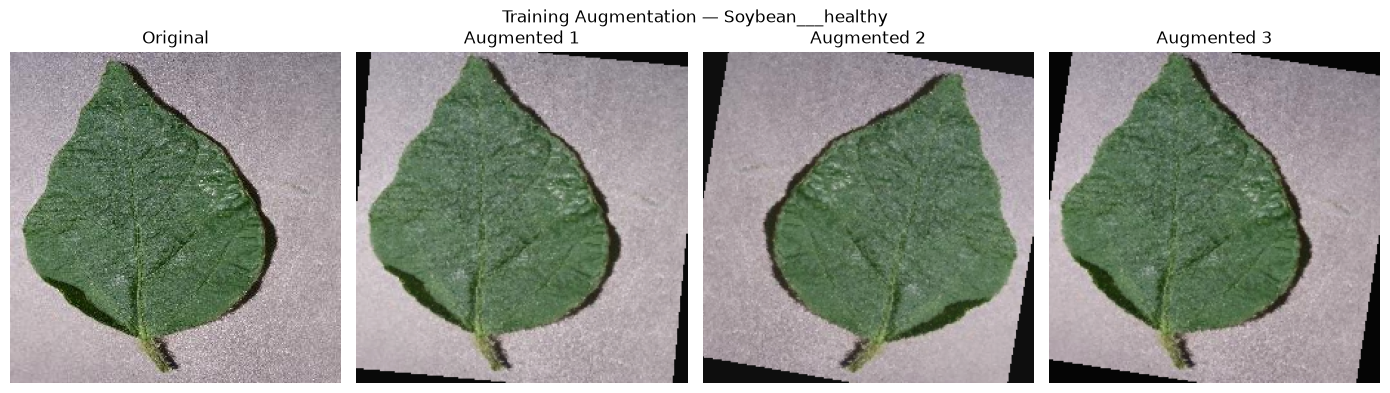

In [18]:
import matplotlib.pyplot as plt
from PIL import Image

# Pick one training image
sample_path = Path(train_df.iloc[0]["image_path"])
sample_label = train_df.iloc[0]["label"]

with Image.open(sample_path) as img:
    original_image = img.convert("RGB")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

# Original image
axes[0].imshow(original_image)
axes[0].set_title("Original")
axes[0].axis("off")

# Three independently augmented versions
for i in range(1, 4):
    augmented_tensor = train_transform(original_image)

    # Reverse ImageNet normalization for display
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    display_tensor = (augmented_tensor * std + mean).clamp(0, 1)
    display_image = display_tensor.permute(1, 2, 0).numpy()

    axes[i].imshow(display_image)
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")

plt.suptitle(f"Training Augmentation — {sample_label}")
plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(r"E:\PlantVillage\data\processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save the three splits
train_df.to_csv(PROCESSED_DIR / "train_metadata.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "validation_metadata.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test_metadata.csv", index=False)

# Reload the saved files to verify them
saved_train = pd.read_csv(PROCESSED_DIR / "train_metadata.csv")
saved_val = pd.read_csv(PROCESSED_DIR / "validation_metadata.csv")
saved_test = pd.read_csv(PROCESSED_DIR / "test_metadata.csv")

print("TRAIN:", len(saved_train))
print("VALIDATION:", len(saved_val))
print("TEST:", len(saved_test))
print("TOTAL:", len(saved_train) + len(saved_val) + len(saved_test))

print("\nUnique classes:")
print("Train:", saved_train["label"].nunique())
print("Validation:", saved_val["label"].nunique())
print("Test:", saved_test["label"].nunique())

assert len(saved_train) == 39236
assert len(saved_val) == 4360
assert len(saved_test) == 10704
assert all(
    df["label"].nunique() == 38
    for df in [saved_train, saved_val, saved_test]
)

print("\nAll metadata checks passed!")

TRAIN: 39236
VALIDATION: 4360
TEST: 10704
TOTAL: 54300

Unique classes:
Train: 38
Validation: 38
Test: 38

All metadata checks passed!


In [1]:
import torch
import torchvision
import pandas as pd

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Training device: CPU")

PyTorch: 2.13.0+cu130
Torchvision: 0.28.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU


In [2]:
import torch
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# RTX 3050 has 4 GB VRAM: start conservatively
BATCH_SIZE = 16

print("Training device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
), "GB")
print("Batch size:", BATCH_SIZE)

Training device: cuda
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU
GPU memory: 4.0 GB
Batch size: 16
